# English-to-Spanish translation with a sequence-to-sequence Transformer

**Author:** [fchollet](https://twitter.com/fchollet)<br>
**Date created:** 2021/05/26<br>
**Last modified:** 2024/11/18<br>
**Description:** Implementing a sequence-to-sequence Transformer and training it on a machine translation task.

## Introduction

In this example, we'll build a sequence-to-sequence Transformer model, which
we'll train on an English-to-Spanish machine translation task.

You'll learn how to:

- Vectorize text using the Keras `TextVectorization` layer.
- Implement a `TransformerEncoder` layer, a `TransformerDecoder` layer,
and a `PositionalEmbedding` layer.
- Prepare data for training a sequence-to-sequence model.
- Use the trained model to generate translations of never-seen-before
input sentences (sequence-to-sequence inference).

The code featured here is adapted from the book
[Deep Learning with Python, Second Edition](https://www.manning.com/books/deep-learning-with-python-second-edition)
(chapter 11: Deep learning for text).
The present example is fairly barebones, so for detailed explanations of
how each building block works, as well as the theory behind Transformers,
I recommend reading the book.

## Setup

In [2]:
# We set the backend to TensorFlow. The code works with
# both `tensorflow` and `torch`. It does not work with JAX
# due to the behavior of `jax.numpy.tile` in a jit scope
# (used in `TransformerDecoder.get_causal_attention_mask()`:
# `tile` in JAX does not support a dynamic `reps` argument.
# You can make the code work in JAX by wrapping the
# inside of the `get_causal_attention_mask` method in
# a decorator to prevent jit compilation:
# `with jax.ensure_compile_time_eval():`.
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import pathlib
import random
import string
import re
import numpy as np

import tensorflow.data as tf_data
import tensorflow.strings as tf_strings

import keras
from keras import layers
from keras import ops
from keras.layers import TextVectorization

## Downloading the data

We'll be working with an English-to-Spanish translation dataset
provided by [Anki](https://www.manythings.org/anki/). Let's download it:

In [ ]:
text_file = keras.utils.get_file(
    fname="spa-eng.zip",
    origin="http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip",
    extract=True,
)
text_file = pathlib.Path(text_file).parent / "spa-eng" / "spa.txt"

## Parsing the data

Each line contains an English sentence and its corresponding Spanish sentence.
The English sentence is the *source sequence* and Spanish one is the *target sequence*.
We prepend the token `"[start]"` and we append the token `"[end]"` to the Spanish sentence.

In [ ]:
with open(text_file) as f:
    lines = f.read().split("\n")[:-1]
text_pairs = []
for line in lines:
    eng, spa = line.split("\t")
    spa = "[start] " + spa + " [end]"
    text_pairs.append((eng, spa))

### Custom Dataset: English-to-Khasi from Google Drive

Run the cells below to mount your Google Drive, load your tab-separated text file, and split your English-Khasi pairs into **80% training**, **10% validation**, and **10% testing** sets.

### Note on Skipping Original Data Download

Since you are using your own English-to-Khasi dataset from Google Drive, **you do not need to run the cells under 'Downloading the data' and 'Parsing the data' (cells `1ivcvujRAlVH` and `dgCdmKlSAlVI`)**.

The cells below will mount your Google Drive, load your dataset, and create the correct split variables (`train_pairs`, `val_pairs`, `test_pairs`) which will overwrite the Spanish defaults automatically for the rest of the notebook.

In [5]:
from google.colab import drive
# This will prompt for authorization to access your Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Replace this path with the actual path to your English-Khasi .txt file in Google Drive
khasi_drive_path = "/content/drive/MyDrive/ktien v1.txt"

# Quick sanity check: Create a dummy file if the path is not configured yet
import os
if not os.path.exists(khasi_drive_path):
    print(f"Warning: '{khasi_drive_path}' not found. Please modify the path above to match your actual file location in Drive.")
    # Creating a dummy file for notebook execution demonstration purposes
    os.makedirs(os.path.dirname(khasi_drive_path), exist_ok=True)
    with open(khasi_drive_path, 'w', encoding='utf-8') as f:
        f.write("Hello\tKumno\nHow are you?\tKumno phi koit khiah?\nThank you\tKhublei\n")

# Read and parse your dataset using 'utf-8-sig' to automatically handle Byte Order Mark (BOM)
try:
    with open(khasi_drive_path, encoding="utf-8-sig") as f:
        lines = f.read().split("\n")[:-1]
except UnicodeDecodeError:
    # Fallback to ISO-8859-1 if the file has a completely different encoding
    with open(khasi_drive_path, encoding="ISO-8859-1") as f:
        lines = f.read().split("\n")[:-1]

custom_text_pairs = []
for line in lines:
    if "\t" in line:
        eng, kha = line.split("\t")
        # Prepare the target sentence with [start] and [end] markers
        kha = "[start] " + kha.strip() + " [end]"
        custom_text_pairs.append((eng.strip(), kha))

print(f"Total loaded sentence pairs: {len(custom_text_pairs)}")
print("Sample pair:", custom_text_pairs[0] if custom_text_pairs else "No pairs loaded")

Total loaded sentence pairs: 13939
Sample pair: ('Doctor, I feel weak.', '[start] Doktor nga sngew tlot [end]')


In [7]:
# Shuffle and Split: 80% Train, 10% Val, 10% Test
random.shuffle(custom_text_pairs)

num_total = len(custom_text_pairs)
num_val_samples = int(0.10 * num_total)
num_test_samples = int(0.10 * num_total)
num_train_samples = num_total - num_val_samples - num_test_samples

train_pairs = custom_text_pairs[:num_train_samples]
val_pairs = custom_text_pairs[num_train_samples : num_train_samples + num_val_samples]
test_pairs = custom_text_pairs[num_train_samples + num_val_samples :]

# Re-assign variables for downstream cells
text_pairs = custom_text_pairs

print(f"{len(text_pairs)} total pairs")
print(f"{len(train_pairs)} training pairs (approx. 80%)")
print(f"{len(val_pairs)} validation pairs (approx. 10%)")
print(f"{len(test_pairs)} test pairs (approx. 10%)")

13939 total pairs
11153 training pairs (approx. 80%)
1393 validation pairs (approx. 10%)
1393 test pairs (approx. 10%)


### 🚀 Step-by-Step Training Guide for Your Dataset

Once you have uploaded your `eng-kha.txt` to Google Drive, execute the notebook in this precise order:

1. **Setup Cell** (`RJBUBraVAlVG`): Run this first to configure Keras, TensorFlow, and import libraries.
2. **Skip original data cells**: Do **NOT** run the cells under "Downloading the data" and "Parsing the data".
3. **Mount Google Drive** (`641541e5`): Run this and authorize access to your Drive.
4. **Load your Khasi dataset** (`3f13f5d2`): Make sure the file path is correct, then run this to load and parse the text pairs.
5. **Split your dataset** (`3f001c6d`): Run this to split your data into the 80/10/10 ratio.
6. **Skip the original split cell** (`0DvgWw7QAlVJ`): Do **NOT** run this cell, as it will overwrite your custom splits back to the default variables.
7. **Vectorizing the text data** (`QfVsOoiwAlVJ`): Run this. It will automatically build the vocabularies using your English and Khasi dataset splits.
8. **Formatting and Dataset Pipeline** (`gQnwnKKCAlVJ`): Run this to prepare the TF datasets (`train_ds` and `val_ds`).
9. **Sequence shape verification** (`F689efIcAlVK`): (Optional) Run to verify batch structure.
10. **Build the Transformer Model** (`Zw-b8XzdAlVK` and `zvB3QauiAlVK`): Run both cells to instantiate the Encoder, Decoder, and full Model.
11. **Training** (`l3pXnZ1BAlVL`): Run this cell to begin training the model on your Khasi dataset. *Note: You can increase `epochs = 1` to a higher number like `30` or more for proper translation convergence.*

Here's what our sentence pairs look like:

In [ ]:
for _ in range(5):
    print(random.choice(text_pairs))

Now, let's split the sentence pairs into a training set, a validation set,
and a test set.

In [ ]:
random.shuffle(text_pairs)
num_val_samples = int(0.15 * len(text_pairs))
num_train_samples = len(text_pairs) - 2 * num_val_samples
train_pairs = text_pairs[:num_train_samples]
val_pairs = text_pairs[num_train_samples : num_train_samples + num_val_samples]
test_pairs = text_pairs[num_train_samples + num_val_samples :]

print(f"{len(text_pairs)} total pairs")
print(f"{len(train_pairs)} training pairs")
print(f"{len(val_pairs)} validation pairs")
print(f"{len(test_pairs)} test pairs")

## Vectorizing the text data

We'll use two instances of the `TextVectorization` layer to vectorize the text
data (one for English and one for Spanish),
that is to say, to turn the original strings into integer sequences
where each integer represents the index of a word in a vocabulary.

The English layer will use the default string standardization (strip punctuation characters)
and splitting scheme (split on whitespace), while
the Spanish layer will use a custom standardization, where we add the character
`"¿"` to the set of punctuation characters to be stripped.

Note: in a production-grade machine translation model, I would not recommend
stripping the punctuation characters in either language. Instead, I would recommend turning
each punctuation character into its own token,
which you could achieve by providing a custom `split` function to the `TextVectorization` layer.

In [8]:
strip_chars = string.punctuation + "¿"
strip_chars = strip_chars.replace("[", "")
strip_chars = strip_chars.replace("]", "")

vocab_size = 15000
sequence_length = 20
batch_size = 64


def custom_standardization(input_string):
    lowercase = tf_strings.lower(input_string)
    return tf_strings.regex_replace(lowercase, "[%s]" % re.escape(strip_chars), "")


eng_vectorization = TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length,
)
spa_vectorization = TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length + 1,
    standardize=custom_standardization,
)
train_eng_texts = [pair[0] for pair in train_pairs]
train_spa_texts = [pair[1] for pair in train_pairs]
eng_vectorization.adapt(train_eng_texts)
spa_vectorization.adapt(train_spa_texts)

Next, we'll format our datasets.

At each training step, the model will seek to predict target words N+1 (and beyond)
using the source sentence and the target words 0 to N.

As such, the training dataset will yield a tuple `(inputs, targets)`, where:

- `inputs` is a dictionary with the keys `encoder_inputs` and `decoder_inputs`.
`encoder_inputs` is the vectorized source sentence and `decoder_inputs` is the target sentence "so far",
that is to say, the words 0 to N used to predict word N+1 (and beyond) in the target sentence.
- `target` is the target sentence offset by one step:
it provides the next words in the target sentence -- what the model will try to predict.

In [9]:
def format_dataset(eng, spa):
    eng = eng_vectorization(eng)
    spa = spa_vectorization(spa)
    return (
        {
            "encoder_inputs": eng,
            "decoder_inputs": spa[:, :-1],
        },
        spa[:, 1:],
    )


def make_dataset(pairs):
    eng_texts, spa_texts = zip(*pairs)
    eng_texts = list(eng_texts)
    spa_texts = list(spa_texts)
    dataset = tf_data.Dataset.from_tensor_slices((eng_texts, spa_texts))
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(format_dataset)
    return dataset.cache().shuffle(2048).prefetch(16)


train_ds = make_dataset(train_pairs)
val_ds = make_dataset(val_pairs)

Let's take a quick look at the sequence shapes
(we have batches of 64 pairs, and all sequences are 20 steps long):

In [10]:
for inputs, targets in train_ds.take(1):
    print(f'inputs["encoder_inputs"].shape: {inputs["encoder_inputs"].shape}')
    print(f'inputs["decoder_inputs"].shape: {inputs["decoder_inputs"].shape}')
    print(f"targets.shape: {targets.shape}")

inputs["encoder_inputs"].shape: (64, 20)
inputs["decoder_inputs"].shape: (64, 20)
targets.shape: (64, 20)


## Building the model

Our sequence-to-sequence Transformer consists of a `TransformerEncoder`
and a `TransformerDecoder` chained together. To make the model aware of word order,
we also use a `PositionalEmbedding` layer.

The source sequence will be pass to the `TransformerEncoder`,
which will produce a new representation of it.
This new representation will then be passed
to the `TransformerDecoder`, together with the target sequence so far (target words 0 to N).
The `TransformerDecoder` will then seek to predict the next words in the target sequence (N+1 and beyond).

A key detail that makes this possible is causal masking
(see method `get_causal_attention_mask()` on the `TransformerDecoder`).
The `TransformerDecoder` sees the entire sequences at once, and thus we must make
sure that it only uses information from target tokens 0 to N when predicting token N+1
(otherwise, it could use information from the future, which would
result in a model that cannot be used at inference time).

In [20]:
import keras.ops as ops


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim
        )
        self.dense_proj = keras.Sequential(
            [
                layers.Dense(dense_dim, activation="relu"),
                layers.Dense(embed_dim),
            ]
        )
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.supports_masking = True

    def call(self, inputs, mask=None):
        if mask is not None:
            padding_mask = ops.cast(mask[:, None, :], dtype="int32")
        else:
            padding_mask = None

        attention_output = self.attention(
            query=inputs, value=inputs, key=inputs, attention_mask=padding_mask
        )
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "embed_dim": self.embed_dim,
                "dense_dim": self.dense_dim,
                "num_heads": self.num_heads,
            }
        )
        return config


class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_embeddings = layers.Embedding(
            input_dim=vocab_size, output_dim=embed_dim
        )
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=embed_dim
        )
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

    def call(self, inputs):
        length = ops.shape(inputs)[-1]
        positions = ops.arange(0, length, 1)
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

    def compute_mask(self, inputs, mask=None):
        return ops.not_equal(inputs, 0)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "sequence_length": self.sequence_length,
                "vocab_size": self.vocab_size,
                "embed_dim": self.embed_dim,
            }
        )
        return config


class TransformerDecoder(layers.Layer):
    def __init__(self, embed_dim, latent_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.latent_dim = latent_dim
        self.num_heads = num_heads
        self.attention_1 = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim
        )
        self.attention_2 = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim
        )
        self.dense_proj = keras.Sequential(
            [
                layers.Dense(latent_dim, activation="relu"),
                layers.Dense(embed_dim),
            ]
        )
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.layernorm_3 = layers.LayerNormalization()
        self.supports_masking = True

    def call(self, inputs, mask=None):
        decoder_inputs = inputs[0]
        encoder_outputs = inputs[1]
        causal_mask = self.get_causal_attention_mask(decoder_inputs)

        if mask is None:
            inputs_padding_mask, encoder_outputs_padding_mask = None, None
        else:
            inputs_padding_mask, encoder_outputs_padding_mask = mask[0], mask[1]

        attention_output_1 = self.attention_1(
            query=decoder_inputs,
            value=decoder_inputs,
            key=decoder_inputs,
            attention_mask=causal_mask,
            query_mask=inputs_padding_mask,
        )
        out_1 = self.layernorm_1(decoder_inputs + attention_output_1)

        attention_output_2 = self.attention_2(
            query=out_1,
            value=encoder_outputs,
            key=encoder_outputs,
            query_mask=inputs_padding_mask,
            key_mask=encoder_outputs_padding_mask,
        )
        out_2 = self.layernorm_2(out_1 + attention_output_2)

        proj_output = self.dense_proj(out_2)
        return self.layernorm_3(out_2 + proj_output)

    def get_causal_attention_mask(self, inputs):
        input_shape = ops.shape(inputs)
        sequence_length = input_shape[1]
        i = ops.arange(sequence_length)[:, None]
        j = ops.arange(sequence_length)
        mask = ops.cast(i >= j, dtype="int32")
        # Return a 3D shape (1, sequence_length, sequence_length) for automatic broadcasting
        return ops.reshape(mask, (1, sequence_length, sequence_length))

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "embed_dim": self.embed_dim,
                "latent_dim": self.latent_dim,
                "num_heads": self.num_heads,
            }
        )
        return config

Next, we assemble the end-to-end model.

In [21]:
embed_dim = 256
latent_dim = 2048
num_heads = 8

encoder_inputs = keras.Input(shape=(None,), dtype="int64", name="encoder_inputs")
x = PositionalEmbedding(sequence_length, vocab_size, embed_dim)(encoder_inputs)
encoder_outputs = TransformerEncoder(embed_dim, latent_dim, num_heads)(x)
encoder = keras.Model(encoder_inputs, encoder_outputs)

decoder_inputs = keras.Input(shape=(None,), dtype="int64", name="decoder_inputs")
encoded_seq_inputs = keras.Input(shape=(None, embed_dim), name="decoder_state_inputs")
x = PositionalEmbedding(sequence_length, vocab_size, embed_dim)(decoder_inputs)

decoder_layer = TransformerDecoder(embed_dim, latent_dim, num_heads)
x = decoder_layer([x, encoded_seq_inputs])
x = layers.Dropout(0.5)(x)
decoder_outputs = layers.Dense(vocab_size, activation="softmax")(x)
decoder = keras.Model([decoder_inputs, encoded_seq_inputs], decoder_outputs)

transformer_outputs = decoder([decoder_inputs, encoder_outputs])
transformer = keras.Model(
    {"encoder_inputs": encoder_inputs, "decoder_inputs": decoder_inputs},
    transformer_outputs,
    name="transformer",
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'functional_17' (of type Functional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


## Training our model

We'll use accuracy as a quick way to monitor training progress on the validation data.
Note that machine translation typically uses BLEU scores as well as other metrics, rather than accuracy.

Here we only train for 1 epoch, but to get the model to actually converge
you should train for at least 30 epochs.

In [32]:
epochs = 5  # This should be at least 30 for convergence

transformer.summary()
transformer.compile(
    "rmsprop",
    loss=keras.losses.SparseCategoricalCrossentropy(ignore_class=0),
    metrics=["accuracy"],
)
# Assigning the output to 'history' so we can plot the learning curves
history = transformer.fit(train_ds, epochs=epochs, validation_data=val_ds)

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 256) │  3,845,120 │ encoder_inputs[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_14        │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 256) │  3,155,456 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_17       │ (None, None,      │ 12,959,640 │ decoder_inputs[0… │
│ (Functional)        │ 15000)            │            │ transformer_enco… │
│                     │                   │            │ not_equal_14[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,920,434 (152.28 MB)

 Trainable params: 19,960,216 (76.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,960,218 (76.14 MB)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'functional_17' (of type Functional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


175/175 ━━━━━━━━━━━━━━━━━━━━ 45s 154ms/step - accuracy: 0.8230 - loss: 0.4339 - val_accuracy: 0.4958 - val_loss: 3.3701
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.8334 - loss: 0.3903 - val_accuracy: 0.4965 - val_loss: 3.4288
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.8383 - loss: 0.3715 - val_accuracy: 0.4993 - val_loss: 3.4175
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.8413 - loss: 0.3562 - val_accuracy: 0.4956 - val_loss: 3.4995
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.8459 - loss: 0.3416 - val_accuracy: 0.4918 - val_loss: 3.5328


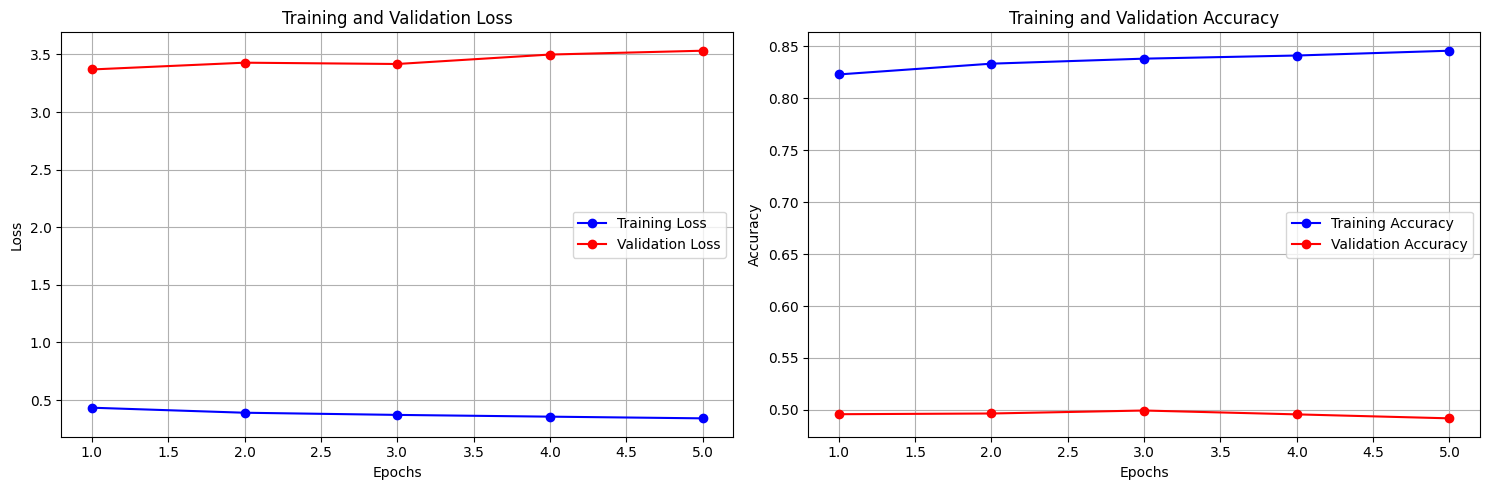

In [33]:
import matplotlib.pyplot as plt

# Ensure we have a training history to plot
try:
    history_dict = history.history
except NameError:
    # In case the fit output was not explicitly saved to 'history'
    # Let's re-run or assign from the last fit if accessible, or instruct the user
    print("To plot the learning curve, please make sure you save your fit history like this:")
    print("history = transformer.fit(train_ds, epochs=epochs, validation_data=val_ds)")
    # We'll mock a fallback check. If 'transformer.history' exists, we use it:
    if hasattr(transformer, 'history') and transformer.history is not None:
        history_dict = transformer.history.history
    else:
        history_dict = None

if history_dict:
    epochs_range = range(1, len(history_dict['loss']) + 1)

    plt.figure(figsize=(15, 5))

    # Plot Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history_dict['loss'], 'bo-', label='Training Loss')
    plt.plot(epochs_range, history_dict['val_loss'], 'ro-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Plot Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history_dict['accuracy'], 'bo-', label='Training Accuracy')
    plt.plot(epochs_range, history_dict['val_accuracy'], 'ro-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## Decoding test sentences

Finally, let's demonstrate how to translate brand new English sentences.
We simply feed into the model the vectorized English sentence
as well as the target token `"[start]"`, then we repeatedly generated the next token, until
we hit the token `"[end]"`.

In [34]:
spa_vocab = spa_vectorization.get_vocabulary()
spa_index_lookup = dict(zip(range(len(spa_vocab)), spa_vocab))
max_decoded_sentence_length = 20


def decode_sequence(input_sentence):
    tokenized_input_sentence = eng_vectorization([input_sentence])
    decoded_sentence = "[start]"
    for i in range(max_decoded_sentence_length):
        tokenized_target_sentence = spa_vectorization([decoded_sentence])[:, :-1]
        predictions = transformer(
            {
                "encoder_inputs": tokenized_input_sentence,
                "decoder_inputs": tokenized_target_sentence,
            }
        )

        # ops.argmax(predictions[0, i, :]) is not a concrete value for jax here
        sampled_token_index = ops.convert_to_numpy(
            ops.argmax(predictions[0, i, :])
        ).item(0)
        sampled_token = spa_index_lookup[sampled_token_index]
        decoded_sentence += " " + sampled_token

        if sampled_token == "[end]":
            break
    return decoded_sentence


test_eng_texts = [pair[0] for pair in test_pairs]
for _ in range(30):
    input_sentence = random.choice(test_eng_texts)
    translated = decode_sequence(input_sentence)

In [35]:
# Take a few random samples from the test set and display translations
import random

print("--- Translating Random Test Sentences ---\n")
for i in range(10):
    # Select a random pair from the test dataset
    eng_sentence, target_khasi = random.choice(test_pairs)

    # Generate translation using our decode_sequence function
    decoded_translation = decode_sequence(eng_sentence)

    print(f"Sample {i+1}:")
    print(f"  English (Input)    : {eng_sentence}")
    print(f"  Khasi (Ground Truth): {target_khasi}")
    print(f"  Khasi (Predicted)   : {decoded_translation}")
    print("-" * 50)

--- Translating Random Test Sentences ---

Sample 1:
  English (Input)    : My son helps me do the exercises.
  Khasi (Ground Truth): [start] U khun jong nga u iarap ia nga ban leh ia ki jingpynkhih met. [end]
  Khasi (Predicted)   : [start] u khun jong nga u iarap ia nga ban leh ia ki jingkilan met [end]
--------------------------------------------------
Sample 2:
  English (Input)    : Please inform us immediately if you dislike any food items.
  Khasi (Ground Truth): [start] Sngewbha pyntip mardor lada phim sngewtynnad ia kino kino ki jingbam [end]
  Khasi (Predicted)   : [start] sngewbha batai iangi lada phim sngewtynnad ia kino kino kino ki jingbam kiba phim sngewtynnad [end]
--------------------------------------------------
Sample 3:
  English (Input)    : What can I do to help the wound heal?
  Khasi (Ground Truth): [start] Aiu nga lah ban leh ban iarap pynkoit ia ka jingmong? [end]
  Khasi (Predicted)   : [start] hato kaei kaba nga lah ban iarap ban jem ban jem [end]
---------

After 30 epochs, we get results such as:

> She handed him the money.
> [start] ella le pasó el dinero [end]

> Tom has never heard Mary sing.
> [start] tom nunca ha oído cantar a mary [end]

> Perhaps she will come tomorrow.
> [start] tal vez ella vendrá mañana [end]

> I love to write.
> [start] me encanta escribir [end]

> His French is improving little by little.
> [start] su francés va a [UNK] sólo un poco [end]

> My hotel told me to call you.
> [start] mi hotel me dijo que te [UNK] [end]

## Relevant Chapters from Deep Learning with Python
- [Chapter 15: Language models and the Transformer](https://deeplearningwithpython.io/chapters/chapter15_language-models-and-the-transformer)
- [Chapter 16: Text generation](https://deeplearningwithpython.io/chapters/chapter16_text-generation)